In [1]:
!pip install -q --no-cache-dir --no-deps numpy==1.26.4

In [2]:
import numpy as np

print("NumPy version:", np.__version__)
print("NumPy path:", np.__file__)

import numpy.random
print("numpy.random: OK")

NumPy version: 1.26.4
NumPy path: /usr/local/lib/python3.12/dist-packages/numpy/__init__.py
numpy.random: OK


In [3]:


!apt-get update -qq
!apt-get install -y -qq git ffmpeg

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


In [4]:
#The Blackwell repository contains compatibility patches specifically intended to bridge the older BEVFormer/MMCV stack to modern PyTorc

%cd /kaggle/working

!rm -rf bevformer-blackwell BEVFormer mmdetection mmdetection3d mmsegmentation mmcv

!git clone https://github.com/nabe2030/bevformer-blackwell.git
!git clone https://github.com/fundamentalvision/BEVFormer.git

!git clone --branch v2.28.2 --depth 1 https://github.com/open-mmlab/mmdetection.git
!git clone --branch v0.17.1 --depth 1 https://github.com/open-mmlab/mmdetection3d.git
!git clone --branch v0.30.0 --depth 1 https://github.com/open-mmlab/mmsegmentation.git
!git clone --branch v1.7.2 --depth 1 https://github.com/open-mmlab/mmcv.git

/kaggle/working
Cloning into 'bevformer-blackwell'...
remote: Enumerating objects: 47, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 47 (delta 4), reused 44 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (47/47), 247.59 KiB | 2.00 MiB/s, done.
Resolving deltas: 100% (4/4), done.
Cloning into 'BEVFormer'...
remote: Enumerating objects: 468, done.
remote: Counting objects: 100% (317/317), done.
remote: Compressing objects: 100% (202/202), done.
remote: Total 468 (delta 175), reused 115 (delta 115), pack-reused 151 (from 1)
Receiving objects: 100% (468/468), 764.65 KiB | 2.92 MiB/s, done.
Resolving deltas: 100% (188/188), done.
Cloning into 'mmdetection'...
remote: Enumerating objects: 1725, done.
remote: Counting objects: 100% (1725/1725), done.
remote: Compressing objects: 100% (1207/1207), done.
remote: Total 1725 (delta 666), reused 905 (delta 500), pack-reused 0 (from 0)
Receiving objects: 100% (1725/1725

In [5]:
#Environment variables

import os

os.environ["TORCH_CUDA_ARCH_LIST"] = "7.5"
os.environ["FORCE_CUDA"] = "1"
os.environ["MMCV_WITH_OPS"] = "1"
os.environ["MAX_JOBS"] = "2"

os.environ["PYTHONPATH"] = (
    "/kaggle/working/BEVFormer:"
    "/kaggle/working/mmdetection3d:"
    + os.environ.get("PYTHONPATH", "")
)

In [6]:
# Install Python dependencies

%cd /kaggle/working

!pip install -q \
    numpy==1.26.4 \
    numba==0.60.0 \
    trimesh==2.35.39 \
    pyquaternion \
    nuscenes-devkit==1.2.0 \
    lyft-dataset-sdk==0.0.8 \
    fvcore==0.1.5.post20221221 \
    terminaltables

/kaggle/working
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 282.0/282.0 kB 5.1 MB/s eta 0:00:00a 0:00:01
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.0/316.0 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.0/63.0 MB 31.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 MB 36.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 78.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.9/57.9 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [7]:
%cd /kaggle/working/mmcv

!pip uninstall -y mmcv mmcv-full -q

!MMCV_WITH_OPS=1 \
  MAX_JOBS=2 \
  TORCH_CUDA_ARCH_LIST="7.5" \
  pip install . --no-build-isolation --no-deps -v

/kaggle/working/mmcv
Using pip 24.1.2 from /usr/local/lib/python3.12/dist-packages/pip (python 3.12)
Processing /kaggle/working/mmcv
  Running command python setup.py egg_info
  /kaggle/working/mmcv/setup.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
    from pkg_resources import DistributionNotFound, get_distribution, parse_version
  /usr/local/lib/python3.12/dist-packages/setuptools/dist.py:765: SetuptoolsDeprecationWarning: License classifiers are deprecated.
  !!

          ********************************************************************************
          Please consider removing the following classifiers in favor of a SPDX license expression:

          License :: OSI Approved :: Apache Software License

          See https://packaging.python.org/en/latest/guides/writing-pyp

In [9]:
#Install MMDetection


%cd /kaggle/working/mmdetection

!pip install . --no-deps --no-build-isolation -q

/kaggle/working/mmdetection
  Preparing metadata (setup.py) ... done


In [10]:
%cd /kaggle/working

!rm -rf /tmp/mmdetection3d
!ln -s /kaggle/working/mmdetection3d /tmp/mmdetection3d

/kaggle/working


In [11]:
## Apply MMDetection3D compatibility patches
#The bevformer-blackwell repository contains compatibility patches for the old OpenMMLab stack.

%cd /kaggle/working

!bash bevformer-blackwell/patches/mmdet3d/01_thc_header_replace.sh
!bash bevformer-blackwell/patches/mmdet3d/02_thc_header_delete.sh
!bash bevformer-blackwell/patches/mmdet3d/03_extern_thcstate_delete.sh
!bash bevformer-blackwell/patches/mmdet3d/04_data_to_data_ptr.sh
!bash bevformer-blackwell/patches/mmdet3d/05_mmcv_version_relax.sh
!bash bevformer-blackwell/patches/mmdet3d/06_numba_errors_path.sh
!bash bevformer-blackwell/patches/mmdet3d/07_spconv_force_register.sh
!bash bevformer-blackwell/patches/mmdet3d/13_spconv_cxx17.sh

/kaggle/working
OK: mmdet3d/ops/ball_query/src/ball_query.cpp
OK: mmdet3d/ops/interpolate/src/interpolate.cpp
OK: mmdet3d/ops/group_points/src/group_points.cpp
OK: patch 01 (THC header replace) applied to 3 files
OK: mmdet3d/ops/knn/src/knn.cpp
OK: mmdet3d/ops/gather_points/src/gather_points.cpp
OK: mmdet3d/ops/furthest_point_sample/src/furthest_point_sample.cpp
OK: patch 02 (THC header delete) applied to 3 files
OK: mmdet3d/ops/ball_query/src/ball_query.cpp
OK: mmdet3d/ops/knn/src/knn.cpp
OK: mmdet3d/ops/interpolate/src/interpolate.cpp
OK: mmdet3d/ops/group_points/src/group_points.cpp
OK: mmdet3d/ops/gather_points/src/gather_points.cpp
OK: mmdet3d/ops/furthest_point_sample/src/furthest_point_sample.cpp
OK: patch 03 (extern THCState delete) applied to 6 files
=== Before patch 04: .data< occurrences ===
48:  const float *points = points_tensor.data<float>();
49:  float *temp = temp_tensor.data<float>();
50:  int *idx = idx_tensor.data<int>();
=== After patch 04: .data_ptr< occurrences =

In [12]:
%cd /kaggle/working/mmdetection3d

!pip uninstall -y mmdet3d -q

!rm -rf build
!find mmdet3d -name "*.so" -delete

!MMCV_WITH_OPS=1 \
FORCE_CUDA=1 \
MAX_JOBS=2 \
TORCH_CUDA_ARCH_LIST="7.5" \
pip install . --no-deps --no-build-isolation -v

/kaggle/working/mmdetection3d
Using pip 24.1.2 from /usr/local/lib/python3.12/dist-packages/pip (python 3.12)
Processing /kaggle/working/mmdetection3d
  Running command python setup.py egg_info
  /usr/local/lib/python3.12/dist-packages/setuptools/_distutils/dist.py:287: UserWarning: Unknown distribution option: 'tests_require'
    warnings.warn(msg)
  /usr/local/lib/python3.12/dist-packages/setuptools/dist.py:765: SetuptoolsDeprecationWarning: License classifiers are deprecated.
  !!

          ********************************************************************************
          Please consider removing the following classifiers in favor of a SPDX license expression:

          License :: OSI Approved :: Apache Software License

          See https://packaging.python.org/en/latest/guides/writing-pyproject-toml/#license for details.
          ********************************************************************************

  !!
    self._finalize_license_expression()
  running egg_

In [14]:
%cd /kaggle/working/mmsegmentation

!pip install . --no-deps --no-build-isolation -q

/kaggle/working/mmsegmentation
  Preparing metadata (setup.py) ... done


In [15]:
%cd /kaggle/working

!mkdir -p /workspace
!rm -rf /workspace/bevformer
!ln -s /kaggle/working/BEVFormer /workspace/bevformer

/kaggle/working


In [16]:
#Apply BEVFormer patches

%cd /kaggle/working

!bash bevformer-blackwell/patches/bevformer/09_dd3d_init_empty.sh
!bash bevformer-blackwell/patches/bevformer/10_datasets_init_guard.sh
!bash bevformer-blackwell/patches/bevformer/11_pipelines_init_guard.sh
!bash bevformer-blackwell/patches/bevformer/12_plugin_init_guard.sh
!bash bevformer-blackwell/patches/bevformer/15_remove_tkinter_typo.sh

/kaggle/working
=== Before patch 09: /workspace/bevformer/projects/mmdet3d_plugin/dd3d/__init__.py ===
from .modeling import *
=== After patch 09: /workspace/bevformer/projects/mmdet3d_plugin/dd3d/__init__.py ===
# Emptied by patches/bevformer/09_dd3d_init_empty.sh
# Reason: dd3d/modeling は Detectron2 依存。BEVFormer 推論パスでは dd3d 不要、
#         かつ v5 image は Detectron2 未 install。plugin load 時の ImportError 回避。
OK: patch 09 (dd3d __init__.py emptied) applied
=== Before patch 10: /workspace/bevformer/projects/mmdet3d_plugin/datasets/__init__.py ===
from .nuscenes_dataset import CustomNuScenesDataset
from .nuscenes_dataset_v2 import CustomNuScenesDatasetV2

from .builder import custom_build_dataset
__all__ = [
    'CustomNuScenesDataset',
    'CustomNuScenesDatasetV2',
]
===
=== After patch 10: /workspace/bevformer/projects/mmdet3d_plugin/datasets/__init__.py ===
from .nuscenes_dataset import CustomNuScenesDataset
try:
    from .nuscenes_dataset_v2 import CustomNuScenesDatasetV2
except ImportEr

In [17]:
from pathlib import Path

path = Path(
    "/kaggle/working/BEVFormer/projects/"
    "mmdet3d_plugin/core/bbox/assigners/"
    "hungarian_assigner_3d.py"
)

text = path.read_text()

text = text.replace(
    "from projects.mmdet3d_plugin.core.bbox.util import normalize_bbox",
    "from ..util import normalize_bbox"
)

path.write_text(text)

6372

In [18]:
from pathlib import Path

datasets_init = Path(
    "/kaggle/working/BEVFormer/projects/"
    "mmdet3d_plugin/datasets/__init__.py"
)

datasets_init.write_text("""from .nuscenes_dataset import CustomNuScenesDataset

try:
    from .nuscenes_dataset_v2 import CustomNuScenesDatasetV2
except ImportError:
    CustomNuScenesDatasetV2 = None

from .builder import custom_build_dataset

__all__ = [
    'CustomNuScenesDataset',
]

if CustomNuScenesDatasetV2 is not None:
    __all__.append('CustomNuScenesDatasetV2')
""")

pipelines_init = Path(
    "/kaggle/working/BEVFormer/projects/"
    "mmdet3d_plugin/datasets/pipelines/__init__.py"
)

pipelines_init.write_text("""from .transform_3d import (
    PadMultiViewImage,
    NormalizeMultiviewImage,
    PhotoMetricDistortionMultiViewImage,
    CustomCollect3D,
    RandomScaleImageMultiViewImage,
)

from .formating import CustomDefaultFormatBundle3D

from .augmentation import (
    CropResizeFlipImage,
    GlobalRotScaleTransImage,
)

try:
    from .dd3d_mapper import DD3DMapper
except ImportError:
    DD3DMapper = None

__all__ = [
    'PadMultiViewImage',
    'NormalizeMultiviewImage',
    'PhotoMetricDistortionMultiViewImage',
    'CustomDefaultFormatBundle3D',
    'CustomCollect3D',
    'RandomScaleImageMultiViewImage',
    'CropResizeFlipImage',
    'GlobalRotScaleTransImage',
]

if DD3DMapper is not None:
    __all__.append('DD3DMapper')
""")

736

In [19]:
DATA_ROOT = "/kaggle/input/datasets/aadimator/nuscenes-mini"
BEVFORMER_ROOT = "/kaggle/working/BEVFormer"
DATA_OUT = "/kaggle/working/data/nuscenes"

import os
os.makedirs(DATA_OUT, exist_ok=True)

In [20]:
from pathlib import Path

p = Path(
    "/kaggle/working/BEVFormer/tools/data_converter/"
    "nuscenes_converter.py"
)

backup = p.with_suffix(".py.bak")

if not backup.exists():
    backup.write_text(p.read_text())

p.write_text(backup.read_text())

26065

In [21]:
from pathlib import Path

p = Path(
    "/kaggle/working/BEVFormer/tools/data_converter/"
    "nuscenes_converter.py"
)

text = p.read_text()

old = "    nusc_can_bus = NuScenesCanBus(dataroot=can_bus_root_path)"

new = """    if osp.exists(osp.join(can_bus_root_path, 'can_bus')):
        nusc_can_bus = NuScenesCanBus(dataroot=can_bus_root_path)
    else:
        print('CAN-bus expansion not found.')
        print('Using nuScenes ego_pose metadata for can_bus.')
        nusc_can_bus = None"""

if old not in text:
    raise RuntimeError("NuScenesCanBus initialization line not found")

text = text.replace(old, new, 1)

p.write_text(text)

26275

In [22]:
from pathlib import Path
import re

p = Path(
    "/kaggle/working/BEVFormer/tools/data_converter/"
    "nuscenes_converter.py"
)

text = p.read_text()

marker = "def _get_can_bus_info"
start = text.find(marker)

if start == -1:
    raise RuntimeError("_get_can_bus_info() not found")

start = text.rfind("\n", 0, start) + 1

match = re.search(
    r"\n(?=def [A-Za-z_][A-Za-z0-9_]*\()",
    text[start + 1:]
)

if match is None:
    raise RuntimeError("Could not find the next top-level function")

end = start + 1 + match.start()

new_function = '''def _get_can_bus_info(nusc, nusc_can_bus, sample):
    lidar_token = sample['data']['LIDAR_TOP']
    lidar_sd = nusc.get('sample_data', lidar_token)
    ego_pose = nusc.get('ego_pose', lidar_sd['ego_pose_token'])

    if nusc_can_bus is None:
        pose = np.array(ego_pose['translation'], dtype=np.float64)
        rotation = np.array(ego_pose['rotation'], dtype=np.float64)

        can_bus = np.zeros(18, dtype=np.float64)
        can_bus[:3] = pose
        can_bus[3:7] = rotation

        quat = Quaternion(rotation)
        yaw = quat.yaw_pitch_roll[0]

        can_bus[-2] = yaw
        can_bus[-1] = np.degrees(yaw)

        return can_bus

    scene_name = nusc.get('scene', sample['scene_token'])['name']
    pose = nusc_can_bus.get_pose(scene_name, sample['timestamp'])

    if pose is None:
        return np.zeros(18, dtype=np.float64)

    last_pose = pose.copy()

    if len(last_pose) > 0:
        last_pose.pop()

    return np.array(last_pose, dtype=np.float64)

'''

text = text[:start] + new_function + text[end:]

p.write_text(text)

print("✓ _get_can_bus_info() restored as a module-level helper")

✓ _get_can_bus_info() restored as a module-level helper


In [23]:
!pip install -q yapf

!pip install -q addict

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 6.7 MB/s eta 0:00:0000:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mmcv-full 1.7.2 requires addict, which is not installed.


In [24]:
#Convert nuScenes Mini
    
%cd /kaggle/working/BEVFormer

!PYTHONPATH=/kaggle/working/BEVFormer:/kaggle/working/mmdetection3d/build/lib.linux-x86_64-cpython-312:/kaggle/working/mmdetection3d \
python tools/create_data.py nuscenes \
    --root-path /kaggle/input/datasets/aadimator/nuscenes-mini \
    --canbus /kaggle/input/datasets/aadimator/nuscenes-mini \
    --version v1.0-mini \
    --max-sweeps 10 \
    --out-dir /kaggle/working/data/nuscenes \
    --extra-tag nuscenes \
    --workers 1

/kaggle/working/BEVFormer
/usr/local/lib/python3.12/dist-packages/mmcv/__init__.py:20: UserWarning: On January 1, 2023, MMCV will release v2.0.0, in which it will remove components related to the training process and add a data transformation module. In addition, it will rename the package names mmcv to mmcv-lite and mmcv-full to mmcv. See https://github.com/open-mmlab/mmcv/blob/master/docs/en/compatibility.md for more details.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/trimesh/resources/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_string
v1.0-mini /kaggle/input/datasets/aadimator/nuscenes-mini
Loading NuScenes tables for version v1.0-mini...
23 category,
8 attribute,
4 visibility,
911 instance,
12 sensor,
120 calibrated_sensor

In [25]:
#Create the required symlink

from pathlib import Path
import shutil

link = Path("/kaggle/working/BEVFormer/data/nuscenes")
target = Path("/kaggle/working/data/nuscenes")

link.parent.mkdir(parents=True, exist_ok=True)

if link.is_symlink() or link.exists():
    if link.is_symlink() or link.is_file():
        link.unlink()
    else:
        shutil.rmtree(link)

link.symlink_to(target, target_is_directory=True)

In [26]:
#Download the pretrained Tiny checkpoint

%cd /kaggle/working/BEVFormer

!mkdir -p ckpts

!wget -q --show-progress \
    -O ckpts/bevformer_tiny_epoch_24.pth \
    https://github.com/zhiqi-li/storage/releases/download/v1.0/bevformer_tiny_epoch_24.pth

/kaggle/working/BEVFormer
ckpts/bevformer_tin 100%[===================>] 382.22M  43.1MB/s    in 6.2s    


In [27]:
#Load BEVFormer configuration

import sys
import torch
import mmcv

from mmcv import Config

sys.path.insert(0, "/kaggle/working/BEVFormer")

cfg = Config.fromfile(
    "/kaggle/working/BEVFormer/projects/"
    "configs/bevformer/bevformer_tiny.py"
)

/usr/local/lib/python3.12/dist-packages/mmcv/__init__.py:20: UserWarning: On January 1, 2023, MMCV will release v2.0.0, in which it will remove components related to the training process and add a data transformation module. In addition, it will rename the package names mmcv to mmcv-lite and mmcv-full to mmcv. See https://github.com/open-mmlab/mmcv/blob/master/docs/en/compatibility.md for more details.
  warnings.warn(


In [29]:
# Register BEVFormer custom modules
import sys

BEVFORMER_ROOT = "/kaggle/working/BEVFormer"

if BEVFORMER_ROOT not in sys.path:
    sys.path.insert(0, BEVFORMER_ROOT)

import projects.mmdet3d_plugin

print("BEVFormer modules registered")

BEVFormer modules registered


/kaggle/working/BEVFormer/projects/mmdet3d_plugin/bevformer/modules/multi_scale_deformable_attn_function.py:18: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.float16)
/kaggle/working/BEVFormer/projects/mmdet3d_plugin/bevformer/modules/multi_scale_deformable_attn_function.py:56: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/kaggle/working/BEVFormer/projects/mmdet3d_plugin/bevformer/modules/multi_scale_deformable_attn_function.py:93: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.float32)
/kaggle/working/BEVFormer/projects/mmdet3d_plugin/bevformer/modules/multi_scale_deformable_attn_function.py:132: FutureWarning: `torch.cuda.amp.custom_

In [30]:
# Build Model
# Build Model
from mmdet3d.models import build_model

model = build_model(
    cfg.model.copy(),
    train_cfg=cfg.get("train_cfg"),
    test_cfg=cfg.get("test_cfg")
)

print("Model built successfully")

/kaggle/working/BEVFormer/projects/mmdet3d_plugin/bevformer/modules/custom_base_transformer_layer.py:94: UserWarning: The arguments `feedforward_channels` in BaseTransformerLayer has been deprecated, now you should set `feedforward_channels` and other FFN related arguments to a dict named `ffn_cfgs`. 
  warnings.warn(
/kaggle/working/BEVFormer/projects/mmdet3d_plugin/bevformer/modules/custom_base_transformer_layer.py:94: UserWarning: The arguments `ffn_dropout` in BaseTransformerLayer has been deprecated, now you should set `ffn_drop` and other FFN related arguments to a dict named `ffn_cfgs`. 
  warnings.warn(
/kaggle/working/BEVFormer/projects/mmdet3d_plugin/bevformer/modules/custom_base_transformer_layer.py:94: UserWarning: The arguments `ffn_num_fcs` in BaseTransformerLayer has been deprecated, now you should set `num_fcs` and other FFN related arguments to a dict named `ffn_cfgs`. 
  warnings.warn(


Model built successfully


/usr/local/lib/python3.12/dist-packages/mmdet3d/models/detectors/mvx_two_stage.py:87: UserWarning: DeprecationWarning: pretrained is a deprecated                     key, please consider using init_cfg
  warnings.warn('DeprecationWarning: pretrained is a deprecated \


In [31]:
# Load checkpoint

from mmcv.runner import load_checkpoint

checkpoint = load_checkpoint(
    model,
    "/kaggle/working/BEVFormer/ckpts/"
    "bevformer_tiny_epoch_24.pth",
    map_location="cpu"
)

device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.eval()

load checkpoint from local path: /kaggle/working/BEVFormer/ckpts/bevformer_tiny_epoch_24.pth


BEVFormer(
  (pts_bbox_head): BEVFormerHead(
    (loss_cls): FocalLoss()
    (loss_bbox): L1Loss()
    (loss_iou): GIoULoss()
    (activate): ReLU(inplace=True)
    (positional_encoding): LearnedPositionalEncoding(num_feats=128, row_num_embed=50, col_num_embed=50)
    (transformer): PerceptionTransformer(
      (encoder): BEVFormerEncoder(
        (layers): ModuleList(
          (0-2): 3 x BEVFormerLayer(
            (attentions): ModuleList(
              (0): TemporalSelfAttention(
                (dropout): Dropout(p=0.1, inplace=False)
                (sampling_offsets): Linear(in_features=512, out_features=128, bias=True)
                (attention_weights): Linear(in_features=512, out_features=64, bias=True)
                (value_proj): Linear(in_features=256, out_features=256, bias=True)
                (output_proj): Linear(in_features=256, out_features=256, bias=True)
              )
              (1): SpatialCrossAttention(
                (dropout): Dropout(p=0.1, inplace=F

In [33]:
# Remove dataloader-only arguments before building the dataset
val_cfg = cfg.data.val.copy()

val_cfg.pop("samples_per_gpu", None)
val_cfg.pop("workers_per_gpu", None)

dataset = build_dataset(val_cfg)

print("Dataset built successfully")
print("Number of samples:", len(dataset))

Dataset built successfully
Number of samples: 81


In [35]:
# Get one validation sample
sample = dataset[0]

print("Sample loaded")
print("Keys:", sample.keys())

Sample loaded
Keys: dict_keys(['img_metas', 'img'])


In [40]:
# Unwrap the DataContainer
img_container = sample["img"][0]

print("Container type:", type(img_container))
print("Container data type:", type(img_container.data))

if isinstance(img_container.data, list):
    print("Number of items inside data:", len(img_container.data))
    print("First item type:", type(img_container.data[0]))
    print("First item shape:", img_container.data[0].shape)
else:
    print("Data shape:", img_container.data.shape)

Container type: <class 'mmcv.parallel.data_container.DataContainer'>
Container data type: <class 'torch.Tensor'>
Data shape: torch.Size([6, 3, 480, 800])


In [43]:
# Prepare BEVFormer input

img_test = sample["img"][0].data.clone().unsqueeze(0).to(device)

img_metas_test = [sample["img_metas"][0].data]

print("Image shape:", img_test.shape)
print("Metadata type:", type(img_metas_test[0]))
print("Number of cameras:", len(img_metas_test[0]["filename"]))

Image shape: torch.Size([1, 6, 3, 480, 800])
Metadata type: <class 'dict'>
Number of cameras: 6


In [44]:
# Run BEVFormer inference

with torch.no_grad():
    new_prev_bev, bbox_results = model.simple_test(
        img_metas=img_metas_test,
        img=img_test,
        prev_bev=None,
        rescale=True
    )

print("Inference completed")
print("BEV feature shape:", new_prev_bev.shape)

/kaggle/working/BEVFormer/projects/mmdet3d_plugin/bevformer/modules/transformer.py:140: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  shift = bev_queries.new_tensor(
/usr/local/lib/python3.12/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Inference completed
BEV feature shape: torch.Size([2500, 1, 256])


In [45]:
#Extract 3D detections

pts_bbox = bbox_results[0]["pts_bbox"]

boxes_3d = pts_bbox["boxes_3d"]
scores_3d = pts_bbox["scores_3d"]
labels_3d = pts_bbox["labels_3d"]

In [72]:
# Get sample token and initialize nuScenes

sample_token = sample["img_metas"][0].data["sample_idx"]

from nuscenes.nuscenes import NuScenes
from pyquaternion import Quaternion

DATA_ROOT = "/kaggle/input/datasets/aadimator/nuscenes-mini"

nusc = NuScenes(
    version="v1.0-mini",
    dataroot=DATA_ROOT,
    verbose=False
)

print("Sample token:", sample_token)

Sample token: 3e8750f331d7499e9b5123e9eb70f2e2


In [73]:
# Convert BEVFormer LiDAR boxes to nuScenes global coordinates

from nuscenes.eval.detection.data_classes import DetectionBox
import numpy as np

class_names = [
    "car",
    "truck",
    "construction_vehicle",
    "bus",
    "trailer",
    "barrier",
    "motorcycle",
    "bicycle",
    "pedestrian",
    "traffic_cone"
]

sample_record = nusc.get("sample", sample_token)

lidar_sd = nusc.get(
    "sample_data",
    sample_record["data"]["LIDAR_TOP"]
)

lidar_cs = nusc.get(
    "calibrated_sensor",
    lidar_sd["calibrated_sensor_token"]
)

ego_pose = nusc.get(
    "ego_pose",
    lidar_sd["ego_pose_token"]
)

lidar_R = Quaternion(
    lidar_cs["rotation"]
).rotation_matrix

ego_R = Quaternion(
    ego_pose["rotation"]
).rotation_matrix

pred_boxes = boxes_3d.tensor.detach().cpu().numpy()
pred_scores = scores_3d.detach().cpu().numpy()
pred_labels = labels_3d.detach().cpu().numpy()

pred_box_list = []

for box, score, label in zip(
    pred_boxes,
    pred_scores,
    pred_labels
):

    x, y, z, length, width, height, yaw, vx, vy = box

    # LiDAR → Ego
    ego_xyz = lidar_R @ np.array([x, y, z])
    ego_xyz += np.array(lidar_cs["translation"])

    # Ego → Global
    global_xyz = ego_R @ ego_xyz
    global_xyz += np.array(ego_pose["translation"])

    # LiDAR → Ego → Global rotation
    box_quat = Quaternion(
        axis=[0, 0, 1],
        radians=float(yaw)
    )

    global_quat = (
        Quaternion(ego_pose["rotation"])
        * Quaternion(lidar_cs["rotation"])
        * box_quat
    )

    pred_box_list.append(
        DetectionBox(
            sample_token=sample_token,
            translation=tuple(global_xyz),
            size=(
                float(width),
                float(length),
                float(height)
            ),
            rotation=tuple(global_quat),
            velocity=(float(vx), float(vy)),
            detection_name=class_names[int(label)],
            detection_score=float(score),
            attribute_name=""
        )
    )

print("Converted boxes:", len(pred_box_list))

Converted boxes: 300


In [74]:


# Filter predictions

score_threshold = 0.30

filtered_boxes = [
    box for box in pred_box_list
    if box.detection_score >= score_threshold
]

print("Predictions >= 0.30:", len(filtered_boxes))

Predictions >= 0.30: 32


In [75]:
# Create prediction structure for official BEVFormer visualizer

pred_data = {
    "results": {
        sample_token: [
            {
                "sample_token": box.sample_token,
                "translation": list(box.translation),
                "size": list(box.size),
                "rotation": list(box.rotation),
                "velocity": list(box.velocity),
                "detection_name": box.detection_name,
                "detection_score": box.detection_score,
                "attribute_name": box.attribute_name
            }
            for box in filtered_boxes
        ]
    }
}

In [78]:
# Initialize nuScenes for the official visualizer

from nuscenes.nuscenes import NuScenes

nusc = NuScenes(
    version="v1.0-mini",
    dataroot="/kaggle/input/datasets/aadimator/nuscenes-mini",
    verbose=False
)

print("nuScenes initialized")

nuScenes initialized


In [80]:
# Run official BEVFormer visualizer

import sys
sys.path.insert(0, "/kaggle/working/BEVFormer/tools/analysis_tools")

import visual

# Give the official visualizer access to nuScenes
visual.nusc = nusc

OUT_PATH = "/kaggle/working/bevformer_sample"

visual.render_sample_data(
    sample_token,
    pred_data=pred_data,
    out_path=OUT_PATH,
    verbose=False
)

print("Visualization generated")

green is ground truth
blue is the predited result
Rendering sample token 3e8750f331d7499e9b5123e9eb70f2e2
Visualization generated


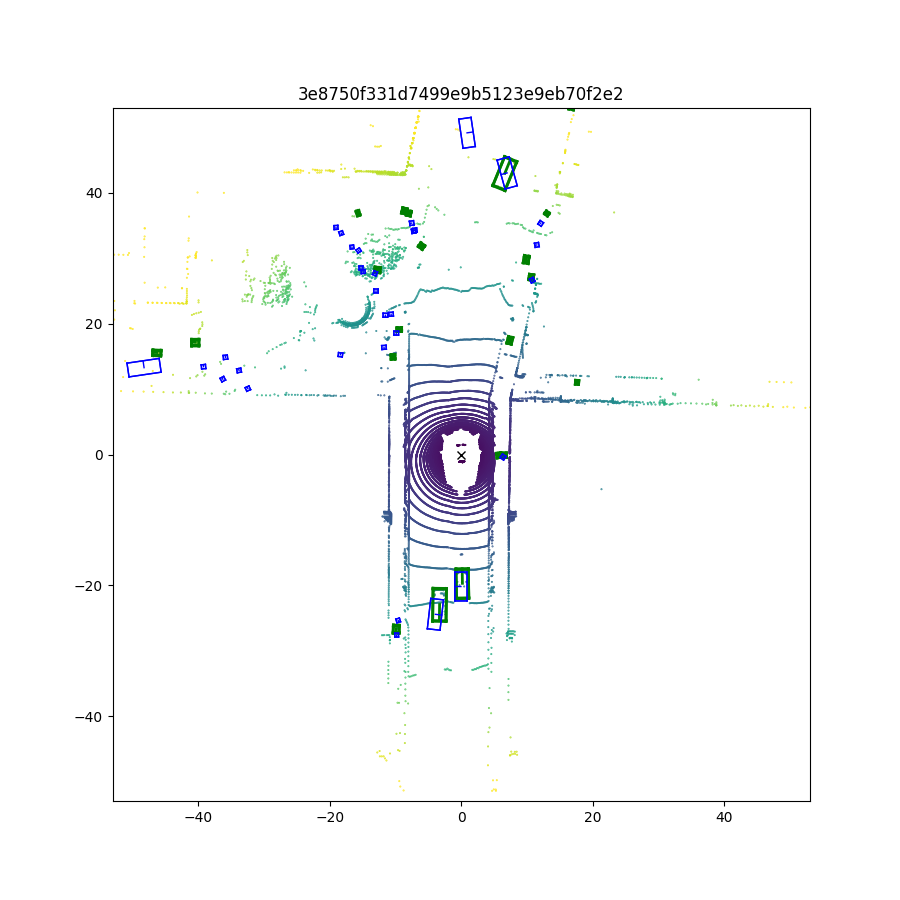

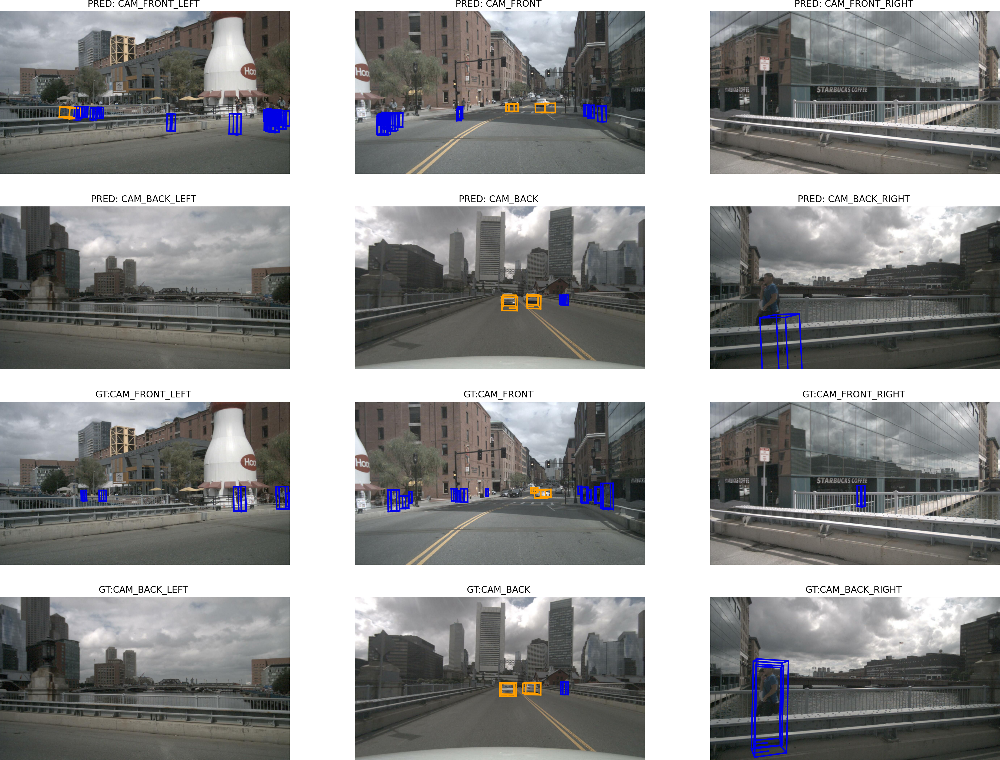

In [81]:
# Display BEVFormer visualization

from IPython.display import display
from PIL import Image

display(
    Image.open(
        "/kaggle/working/bevformer_sample_bev.png"
    )
)

display(
    Image.open(
        "/kaggle/working/bevformer_sample_camera.png"
    )
)